# Moodify : parties 4 et 5 (recommandation et API)

Projet Analyse sémantique et systèmes de recommandation, thème 4 (musique selon l'humeur).

Ce notebook contient :
- **Partie 4, recommandation** : la formule de score, le classement des morceaux et l'explication de chaque recommandation (`backend/recommendation/`).
- **Partie 5, API** : le backend FastAPI que le front Next.js appelle (`backend/main.py`, `backend/schemas/`).

Comment les parties se branchent :
- le dataset (684 morceaux) vient de `data/moodify_dataset.csv`
- toutes les similarités sémantiques viennent du module de la partie 3 (`src/moodify/semantic.py`, notebook 02). On utilise son modèle SBERT `paraphrase-multilingual-mpnet-base-v2` et sa calibration
- le front envoie le questionnaire au format défini dans `frontend/docs/api-contract.md`, et notre API répond dans ce même format

Pour l'exécuter sur Colab : Exécution > Modifier le type d'exécution > **GPU T4** (le modèle mpnet est plus gros que MiniLM, l'encodage du catalogue est beaucoup plus rapide sur GPU), puis lancer les cellules dans l'ordre. Le notebook télécharge lui-même le dépôt du projet, pas besoin d'importer de fichier.

Plan :
1. Installation
2. Historique : nos premiers tests avec MiniLM et les erreurs trouvées
3. Les mêmes tests avec mpnet (le modèle choisi par la partie 3)
4. La formule de score
5. Classement et explications
6. Cas d'usage
7. L'API FastAPI
8. Résumé pour l'oral

## 1. Installation

In [1]:
#on récupère le projet complet (module NLP, dataset, front...)
!git clone -q https://github.com/koneaziz/moodify.git
%cd moodify
!pip install -q sentence-transformers fastapi httpx

/content/moodify


In [2]:
import sys
import re
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#pour pouvoir importer le module de la partie 3 (src/moodify) et notre code (backend/)
sys.path[:0] = ["src", "."]

from moodify.semantic import SemanticMatcher

In [3]:
#chargement du module de la partie 3 : dataset + modèle mpnet + embeddings du catalogue
#(environ 1 min sur GPU, plus long sur processeur)
sm = SemanticMatcher()
print(len(sm.tracks), "morceaux")
print("modèle :", sm.encoder.model_name if hasattr(sm.encoder, "model_name") else sm.encoder.name)

684 morceaux
modèle : sentence-transformers/paraphrase-multilingual-mpnet-base-v2


## 2. Historique : nos premiers tests avec MiniLM

Avant que la partie 3 choisisse son modèle, on avait commencé avec `paraphrase-multilingual-MiniLM-L12-v2` (la version multilingue du modèle de l'exemple du sujet) et nos propres blocs d'humeur. On a gardé ici les erreurs qu'on a trouvées, parce qu'elles expliquent nos choix.

**Erreur 1 : le modèle s'accroche au mot "musique".**

| | je suis triste ce soir | une chanson mélancolique | musique pour faire la fête | j'ai le cafard |
|---|---|---|---|---|
| je suis triste ce soir | 1.00 | 0.35 | 0.28 | 0.56 |
| une chanson mélancolique | 0.35 | 1.00 | **0.72** | 0.44 |

"Une chanson mélancolique" et "musique pour faire la fête" avaient 0.72 alors que ce sont deux émotions opposées. Le modèle voyait d'abord que les deux phrases parlent de musique : le sujet de la phrase pesait plus que l'émotion. Avec des phrases sans le mot musique ("je me sens mélancolique", "j'ai envie de faire la fête"...), les émotions étaient mieux séparées (0.41 à 0.52 entre triste et fête, 0.56 à 0.69 entre les phrases tristes).

**Erreur 2 : des contextes mal reconnus.**
- "Je révise tard le soir pour mes partiels" donnait le contexte *Sommeil & méditation* au lieu de *Étude & travail* (le modèle retenait "tard le soir")
- "Une ambiance tendre et intime, un peu rêveuse" + "Dîner en tête-à-tête avec ma copine" donnait *Calme & détente* et *Soirée & fête* au lieu de *Romance & sensualité* et *Moment à deux*

On avait corrigé ça en réécrivant nos phrases de blocs sans "musique / son / ambiance" et en ajoutant des formulations ("réviser mes partiels", "dîner en tête-à-tête"). Les deux cas étaient alors bien reconnus.

**Erreur 3 : l'état de la personne au lieu de son souhait.**
"J'ai besoin de souffler, de laisser retomber la pression" donnait *Colère & défoulement*, avec Rage Against the Machine en premier. Le modèle reconnaissait la tension (l'état) et pas l'envie de se calmer (le souhait).

**Ce qui a changé ensuite** : la partie 3 a comparé plusieurs modèles (notebook 02) et a choisi `paraphrase-multilingual-mpnet-base-v2`, meilleur sur les paraphrases (7/8 contre 6/8 pour MiniLM) et sur le jeu gold (P@5 = 0.77 contre 0.59). Pour que tout le projet soit cohérent, on utilise maintenant son module et ses blocs (`data/blocks.json`). On refait nos tests avec ce modèle.

## 3. Les mêmes tests avec mpnet

In [4]:
phrases = ["je suis triste ce soir",
           "une chanson mélancolique",
           "musique pour faire la fête",
           "j'ai le cafard"]
emb = sm.encoder.encode(phrases)
pd.DataFrame(emb @ emb.T, index=phrases, columns=phrases).round(2)

,je suis triste ce soir,une chanson mélancolique,musique pour faire la fête,j'ai le cafard
je suis triste ce soir,1.00,0.50,0.33,0.59
une chanson mélancolique,0.50,1.00,0.67,0.48
musique pour faire la fête,0.33,0.67,1.00,0.37
j'ai le cafard,0.59,0.48,0.37,1.00


Résultat avec mpnet :
- "une chanson mélancolique" / "musique pour faire la fête" passe de 0.72 à **0.67**
- "une chanson mélancolique" / "je suis triste ce soir" passe de 0.35 à **0.50**
- "j'ai le cafard" / "je suis triste ce soir" reste bien reconnu (**0.59**)

C'est mieux, mais le problème n'a pas disparu : mpnet aussi rapproche deux phrases parce qu'elles parlent de musique. Même avec un meilleur modèle, il faut faire attention à la façon dont on écrit les textes qu'on compare.

## 4. La formule de score (partie 4)

On reprend la formule de l'exemple du sujet :

$$Score = \frac{\sum W_i \times S_i}{\sum W_i}$$

Chaque morceau a 6 scores Si entre 0 et 1 :

| Critère | Ce qu'il mesure | Calcul | Poids |
|---|---|---|---|
| description | les textes de l'utilisateur ressemblent au morceau | score sémantique de la partie 3 (3 vues : globale, humeur, contexte), recalé entre 0 et 1 | 0.30 |
| humeur | les blocs d'humeur du morceau correspondent au profil | moyenne du profil sur les `mood_blocks` du morceau | 0.25 |
| contexte | pareil avec le contexte d'écoute | moyenne du profil sur les `context_blocks` | 0.15 |
| genre | le genre fait partie des genres cochés | 1 ou 0 | 0.15 |
| energie | l'énergie est proche de celle demandée (échelle 1-5) | 1 - écart/4 | 0.10 |
| artiste | c'est un artiste préféré | 1 ou 0 | 0.05 |

Pourquoi ces poids :
- **70 % du score est sémantique** (description + humeur + contexte), comme le demande le sujet ("contextuelle et sémantique, et non purement numérique")
- la description pèse le plus : c'est le texte le plus riche
- l'humeur vient ensuite, c'est le cœur du thème
- le genre est une préférence importante mais on ne voulait pas qu'il écrase le reste
- l'artiste n'est qu'un bonus, sinon on ne recommanderait que des artistes que l'utilisateur connaît déjà

Autres choix :
- **calibration** : la partie 3 a mesuré que son score sémantique va en pratique de 0.29 à 0.53 (5e et 99,5e centile). On le recale donc : (s - 0.29) / (0.53 - 0.29), borné entre 0 et 1. Sans ça, ce critère serait toujours faible à côté des autres.
- **normalisation min-max du profil** : le bloc le plus proche vaut 1 et le plus loin 0, parce que les cosinus bruts des blocs sont très serrés
- **critère non rempli** : il n'est pas calculé et son poids ne compte pas dans la somme des Wi, donc on ne pénalise pas l'utilisateur
- **seuils** (étape 5) : 0.65 et plus = très forte correspondance, de 0.45 à 0.65 = bonne, en dessous = partielle

La cellule suivante écrit le fichier `backend/recommendation/scoring.py` (c'est le fichier du dépôt). Il faut l'exécuter avant tout ce qui utilise `scoring`.

In [5]:
%%writefile backend/recommendation/scoring.py
"""Formule de score de la partie 4 (recommandation).

On utilise le module NLP de la partie 3 (src/moodify/semantic.py) pour toutes les similarités,
puis on combine 6 critères avec la formule de l'exemple du sujet :
    score = somme(Wi * Si) / somme(Wi)
Tout est expliqué dans notebooks/03_recommandation_api.ipynb.
"""
import numpy as np
import pandas as pd

from backend.personalization import construire_profil_utilisateur

#poids des critères : 70 % sémantique (description + humeur + contexte), 30 % préférences cochées
POIDS = {
    "description": 0.30,
    "humeur": 0.25,
    "contexte": 0.15,
    "genre": 0.15,
    "energie": 0.10,
    "artiste": 0.05,
}

#calibration donnée par la partie 3 (notebook 02, section 7.3) : 5e et 99,5e centile du score sémantique
COS_LOW = 0.29
COS_HIGH = 0.53

#partie 6 : multiplicateur du score d'un morceau chanté quand l'utilisateur demande de l'instrumental
PENALITE_CHANTE = 0.6

#seuils d'interprétation du score final (étape 5 de l'exemple du sujet)
SEUILS = [(0.65, "Très forte correspondance"), (0.45, "Bonne correspondance"), (0.0, "Correspondance partielle")]


def separer(texte):
    #"calme|doux|serein" -> ["calme", "doux", "serein"]
    return [x.strip() for x in str(texte).split("|") if x.strip()]


def niveau(score):
    for seuil, libelle in SEUILS:
        if score >= seuil:
            return libelle
    return SEUILS[-1][1]


def normaliser(scores):
    #min-max : le bloc le plus proche vaut 1 et le plus loin 0 (les cosinus bruts sont très serrés)
    if not scores:
        return {}
    mini, maxi = min(scores.values()), max(scores.values())
    return {b: (s - mini) / (maxi - mini + 1e-9) for b, s in scores.items()}


def construire_profil(sm, requete):
    """Profil utilisateur de la partie 6 (backend/personalization).
    requete = le questionnaire du front, ou l'ancien format {"textes", "humeur", "contexte",
    "genres", "artistes", "energie"} (toujours accepté, par exemple dans le notebook 03)."""
    return construire_profil_utilisateur(sm, requete)


def moyenne_blocs(blocs_morceau, profil_blocs):
    #moyenne du profil sur les blocs du morceau (comme un poste qui "demande" certains blocs)
    valeurs = [profil_blocs[b] for b in separer(blocs_morceau) if b in profil_blocs]
    return float(np.mean(valeurs)) if valeurs else 0.0


def calculer_scores(sm, profil):
    """Calcule les critères Si de tous les morceaux et le score final."""
    df = sm.tracks
    S = pd.DataFrame(index=df.index)

    #score sémantique de la partie 3 (3 vues du morceau), recalé entre 0 et 1
    brut = sm.semantic_score(profil["textes"])
    S["description"] = np.clip((brut - COS_LOW) / (COS_HIGH - COS_LOW), 0, 1)
    S["humeur"] = df["mood_blocks"].fillna("").apply(lambda b: moyenne_blocs(b, profil["blocs_humeur"]))

    #un critère que l'utilisateur n'a pas rempli n'est pas calculé (son poids ne compte pas)
    if profil["blocs_contexte"]:
        S["contexte"] = df["context_blocks"].fillna("").apply(lambda b: moyenne_blocs(b, profil["blocs_contexte"]))
    if profil["genres"]:
        S["genre"] = df["genre"].isin(profil["genres"]).astype(float)
    if profil["energie"]:
        S["energie"] = 1 - abs(df["energy"].astype(int) - profil["energie"]) / 4
    if profil["artistes"]:
        noms = (df["artist"].fillna("") + " " + df["featured_artists"].fillna("")).str.lower()
        S["artiste"] = noms.apply(lambda n: any(a in n for a in profil["artistes"])).astype(float)

    #formule du sujet : score = somme(Wi * Si) / somme(Wi)
    poids = {c: POIDS[c] for c in S.columns}
    score = sum(S[c] * poids[c] for c in S.columns) / sum(poids.values())

    #contraintes du profil (partie 6) : genres refusés exclus, morceaux chantés pénalisés si
    #l'utilisateur veut de l'instrumental
    if profil.get("genres_exclus"):
        score = score.where(~df["genre"].isin(profil["genres_exclus"]), 0.0)
    if profil.get("instrumental"):
        instru = (df["language"].fillna("") == "instrumental") | (df["instrumentalness"].fillna(0) >= 0.5)
        score = score.where(instru, score * PENALITE_CHANTE)
    return S, poids, score, brut

Overwriting backend/recommendation/scoring.py


In [6]:
import importlib
import backend.recommendation.scoring as scoring
importlib.reload(scoring)

<module 'backend.recommendation.scoring' from '/content/moodify/backend/recommendation/scoring.py'>

### Retour sur nos erreurs : les profils avec mpnet
Maintenant que `scoring.py` est écrit, on refait les tests de profil de l'historique (section 2).

In [7]:
cas_test = {
    "Révision": {"humeur": ["Je suis épuisé après ma journée. J'ai besoin de quelque chose de doux et apaisant."],
                 "contexte": ["Je révise tard le soir pour mes partiels"]},
    "Soirée romantique": {"humeur": ["Une ambiance tendre et intime, un peu rêveuse."],
                          "contexte": ["Dîner en tête-à-tête avec ma copine"]},
    "Souffler": {"humeur": ["J'ai besoin de souffler, de laisser retomber la pression."]},
}
lignes = []
for nom, requete in cas_test.items():
    p = scoring.construire_profil(sm, requete)
    lignes.append({"cas": nom, "humeur attendue": "", "humeur mpnet": p["humeur_dominante"],
                   "contexte mpnet": p["contexte_dominant"]})
tableau = pd.DataFrame(lignes)
tableau["humeur attendue"] = ["Calme & détente", "Romance & sensualité", "Calme & détente"]
tableau

,cas,humeur attendue,humeur mpnet,contexte mpnet
0,Révision,Calme & détente,Calme & détente,Soirée & fête
1,Soirée romantique,Romance & sensualité,Romance & sensualité,Moment à deux
2,Souffler,Calme & détente,Calme & détente,None


Résultat avec mpnet :
- **soirée romantique** : *Romance & sensualité* et *Moment à deux*, c'est juste (MiniLM se trompait avec nos premiers blocs)
- **souffler** : *Calme & détente*, c'est juste (MiniLM donnait *Colère & défoulement*). L'erreur 3 est corrigée par le changement de modèle
- **révision** : l'humeur est juste mais le contexte est *Soirée & fête* au lieu d'*Étude & travail*. MiniLM donnait *Sommeil & méditation*. Les deux modèles se font avoir par "tard le soir", et mpnet le rapproche de "soirée". **C'est une erreur qui reste.**

Pour la révision, c'est moins grave dans l'application : le questionnaire du front a une case "Studying" que l'API transforme en "pour réviser et étudier", et avec cette phrase le contexte trouvé est bien *Étude & travail* (voir le test de l'API en section 7). On a quand même proposé à la partie 3 d'ajouter une phrase comme "réviser tard le soir" dans le bloc *Étude & travail*.

Remarque : les blocs de la partie 3 contiennent eux aussi des phrases avec "musique", "ambiance" ou "sons" (par exemple "musique douce et apaisante pour se détendre"). Si une erreur revient, ça peut venir de là, et on l'a signalé à la partie 3. Il y a aussi un bloc *Concentration* dans ses blocs qui n'existe pas dans les `mood_blocks` du dataset : il apparaît dans le profil mais il ne compte pas dans le score d'humeur des morceaux.

In [8]:
requete_exemple = {
    "textes": ["Je suis épuisé après ma journée. J'ai besoin de quelque chose de doux et apaisant.",
               "Je révise tard le soir pour mes partiels"],
    "humeur": ["Je suis épuisé après ma journée. J'ai besoin de quelque chose de doux et apaisant."],
    "contexte": ["Je révise tard le soir pour mes partiels"],
    "genres": ["Lo-fi / Chill", "Classique"],
    "artistes": [],
    "energie": 2,
}
profil = scoring.construire_profil(sm, requete_exemple)
S, poids, score, brut = scoring.calculer_scores(sm, profil)
print("Poids utilisés :", poids)

tableau = S.copy()
tableau["SCORE"] = score
tableau.insert(0, "morceau", sm.tracks["title"] + " (" + sm.tracks["artist"] + ")")
tableau.sort_values("SCORE", ascending=False).head(10).round(3)

Poids utilisés : {'description': 0.3, 'humeur': 0.25, 'contexte': 0.15, 'genre': 0.15, 'energie': 0.1}


,morceau,description,humeur,contexte,genre,energie,SCORE
609,i'm closing my eyes (potsu),0.836,0.676,0.367,1.0,0.75,0.737
544,Give It Away (Zero 7),0.488,1.000,0.418,1.0,0.75,0.720
285,A Drop in the Ocean (Ron Pope),0.364,0.873,0.661,1.0,1.00,0.712
604,Moretime (Nightmares On Wax),0.618,0.514,0.709,1.0,1.00,0.705
353,In The Waiting Line (Zero 7),0.294,1.000,0.418,1.0,1.00,0.685
507,Hell Is Round The Corner (Tricky),0.310,0.873,0.575,1.0,0.75,0.655
612,Monday Loop (Tomppabeats),0.380,0.676,0.574,1.0,1.00,0.651
539,Stay The Same (Bonobo),0.257,1.000,0.418,1.0,0.75,0.647
468,Heart's Content (Brandi Carlile),0.686,0.873,0.575,0.0,1.00,0.643
603,Baptism (Roots Manuva),0.319,1.000,0.418,1.0,0.50,0.640


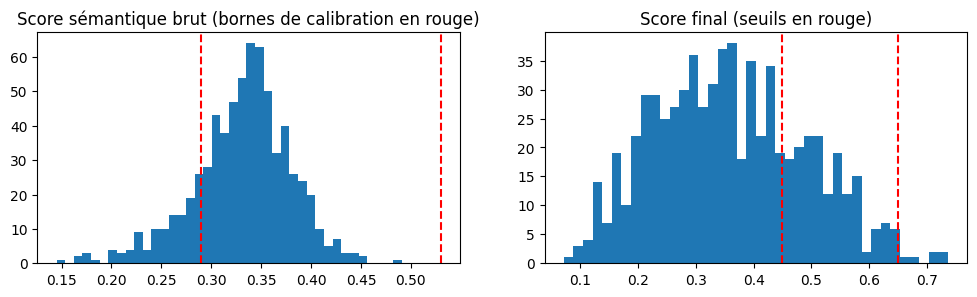

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].hist(brut, bins=40)
axes[0].axvline(scoring.COS_LOW, color="red", linestyle="--")
axes[0].axvline(scoring.COS_HIGH, color="red", linestyle="--")
axes[0].set_title("Score sémantique brut (bornes de calibration en rouge)")
axes[1].hist(score, bins=40)
axes[1].axvline(0.65, color="red", linestyle="--")
axes[1].axvline(0.45, color="red", linestyle="--")
axes[1].set_title("Score final (seuils en rouge)")
plt.show()

Ce qu'on observe :
- à gauche, le score sémantique brut va d'environ 0.15 à 0.50 pour cette requête. Tout ce qui est sous 0.29 est ramené à 0, et le meilleur morceau arrive à 0.84 après calibration. Sans la calibration, ce critère serait toujours petit à côté des autres.
- à droite, seule une poignée de morceaux dépasse 0.65 (environ 5 sur 684) et la majorité est sous 0.45. Les seuils sont donc cohérents : le top 3 est en "très forte correspondance" parce que ce sont vraiment les meilleurs. Avec MiniLM, les 10 premiers dépassaient tous 0.65.
- le contexte de cette requête est encore *Soirée & fête* (l'erreur de la révision vue au-dessus). Ça se voit dans les scores de contexte assez bas (0.37 à 0.71).

## 5. Classement et explications

Le sujet demande pour chaque recommandation : le morceau, son score, les principaux critères et une explication basée sur l'analyse sémantique.
- **principaux critères** : les 3 critères qui contribuent le plus au score, avec contribution = Wi x Si / somme(Wi)
- **explication** : on assemble des phrases toutes faites avec les scores (méthode par règles, le sujet dit que l'IA générative n'est pas obligatoire)
- **un seul morceau par artiste** dans le top 3, pour qu'il soit varié

In [10]:
%%writefile backend/recommendation/recommender.py
"""Classement des morceaux et explications (partie 4).

Pour chaque recommandation : le morceau, son score, les principaux critères et une
explication construite avec des phrases toutes faites (pas d'IA générative).
"""
from .scoring import calculer_scores, construire_profil, niveau, separer

NOMS = {"description": "Proche de votre description", "humeur": "Humeur", "contexte": "Contexte d'écoute",
        "genre": "Genre préféré", "energie": "Énergie", "artiste": "Artiste préféré"}


def meilleur_bloc(blocs_morceau, profil_blocs):
    blocs = [b for b in separer(blocs_morceau) if b in profil_blocs]
    return max(blocs, key=profil_blocs.get) if blocs else ""


def phrase(critere, m, valeur, profil):
    #une phrase par critère, remplie avec les scores
    if critere == "description":
        return f"sa description est proche de ce que vous avez écrit ({valeur:.0%})"
    if critere == "humeur":
        return f"son ambiance « {meilleur_bloc(m['mood_blocks'], profil['blocs_humeur'])} » correspond à votre humeur ({valeur:.0%})"
    if critere == "contexte":
        return f"il colle au contexte « {meilleur_bloc(m['context_blocks'], profil['blocs_contexte'])} » ({valeur:.0%})"
    if critere == "genre":
        return f"c'est du {m['genre']}, un genre que vous aimez"
    if critere == "energie":
        return f"son énergie ({m['energy']}/5) est proche de celle demandée ({profil['energie']}/5)"
    return f"c'est un morceau de {m['artist']}, un de vos artistes préférés"


def recommander(sm, requete, top_k=3):
    profil = construire_profil(sm, requete)
    S, poids, score, brut = calculer_scores(sm, profil)
    df = sm.tracks
    total = sum(poids.values())

    resultats, artistes_vus = [], set()
    for i in score.sort_values(ascending=False).index:
        m = df.loc[i].fillna("")
        #un seul morceau par artiste pour avoir un top varié
        if m["artist"] in artistes_vus:
            continue
        artistes_vus.add(m["artist"])

        s = float(score[i])
        #contribution de chaque critère = Wi * Si / somme(Wi)
        contrib = {c: float(S.loc[i, c] * poids[c] / total) for c in poids}
        principaux = [c for c in sorted(contrib, key=contrib.get, reverse=True) if S.loc[i, c] > 0][:3]
        resultats.append({
            "rang": len(resultats) + 1,
            "track_id": str(m["track_id"]),
            "titre": m["title"],
            "artiste": m["artist"],
            "genre": m["genre"],
            "humeurs": separer(m["mood"]),
            "blocs_humeur": separer(m["mood_blocks"]),
            "contextes": separer(m["context"]),
            "energie": int(m["energy"]),
            "score": round(s, 3),
            "niveau": niveau(s),
            "cosinus_brut": round(float(brut[i]), 3),
            "criteres": {c: round(float(S.loc[i, c]), 3) for c in S.columns},
            "contributions": {c: round(v, 3) for c, v in contrib.items()},
            "principaux_criteres": [NOMS[c] for c in principaux],
            "explication": f"« {m['title']} » de {m['artist']} est recommandé car "
                           + ", ".join(phrase(c, m, S.loc[i, c], profil) for c in principaux)
                           + f". {niveau(s)} (score {s:.0%}).",
        })
        if len(resultats) == top_k:
            break

    top2 = sorted(profil["blocs_humeur"], key=profil["blocs_humeur"].get, reverse=True)[:2]
    synthese = f"Vous cherchez une ambiance « {top2[0]} » / « {top2[1]} »"
    if profil["contexte_dominant"]:
        synthese += f", pour un contexte « {profil['contexte_dominant']} »"
    if profil["energie"]:
        synthese += f", énergie {profil['energie']}/5"
    if profil["genres"]:
        synthese += ", genres : " + ", ".join(profil["genres"])

    return {"profil": {**profil, "synthese": profil.get("synthese") or synthese + "."}, "recommandations": resultats, "poids": poids,
            "scores": score, "criteres": S}

Overwriting backend/recommendation/recommender.py


In [11]:
import backend.recommendation.recommender as recommender
importlib.reload(recommender)


def afficher(res):
    print("PROFIL :", res["profil"]["synthese"])
    for r in res["recommandations"]:
        print()
        print(f"{r['rang']}. {r['titre']} - {r['artiste']} [{r['genre']}]")
        print("   score :", r["score"], "-", r["niveau"])
        print("   critères :", r["criteres"])
        print("   principaux critères :", ", ".join(r["principaux_criteres"]))
        print("  ", r["explication"])


resultat = recommender.recommander(sm, requete_exemple)
afficher(resultat)

PROFIL : Vous cherchez une ambiance « Calme & détente » / « Romance & sensualité », pour un contexte « Soirée & fête », énergie 2/5, genres : Lo-fi / Chill, Classique.

1. i'm closing my eyes - potsu [Lo-fi / Chill]
   score : 0.737 - Très forte correspondance
   critères : {'description': 0.836, 'humeur': 0.676, 'contexte': 0.367, 'genre': 1.0, 'energie': 0.75}
   principaux critères : Proche de votre description, Humeur, Genre préféré
   « i'm closing my eyes » de potsu est recommandé car sa description est proche de ce que vous avez écrit (84%), son ambiance « Calme & détente » correspond à votre humeur (68%), c'est du Lo-fi / Chill, un genre que vous aimez. Très forte correspondance (score 74%).

2. Give It Away - Zero 7 [Lo-fi / Chill]
   score : 0.72 - Très forte correspondance
   critères : {'description': 0.488, 'humeur': 1.0, 'contexte': 0.418, 'genre': 1.0, 'energie': 0.75}
   principaux critères : Humeur, Genre préféré, Proche de votre description
   « Give It Away » de Zero

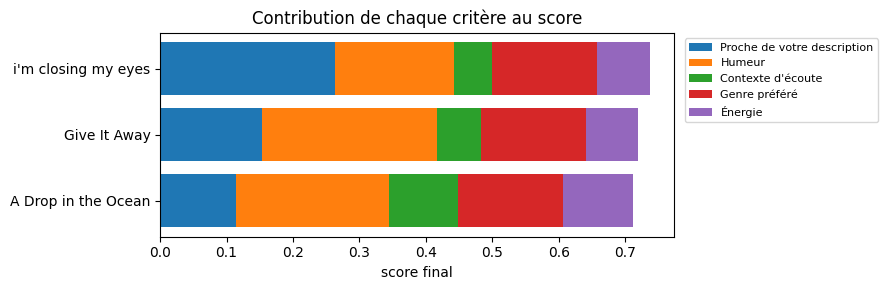

In [12]:
#barres empilées : la part de chaque critère dans le score
recos = resultat["recommandations"]
noms = [r["titre"] for r in recos][::-1]
gauche = np.zeros(len(recos))
plt.figure(figsize=(9, 3))
for c in recos[0]["contributions"]:
    valeurs = np.array([r["contributions"][c] for r in recos][::-1])
    plt.barh(noms, valeurs, left=gauche, label=recommender.NOMS[c])
    gauche += valeurs
plt.xlabel("score final")
plt.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("Contribution de chaque critère au score")
plt.tight_layout()
plt.show()

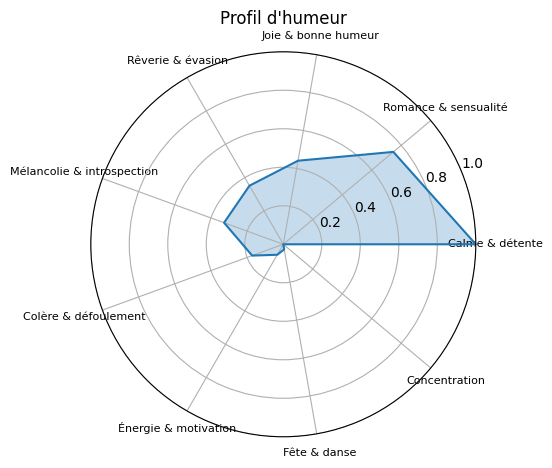

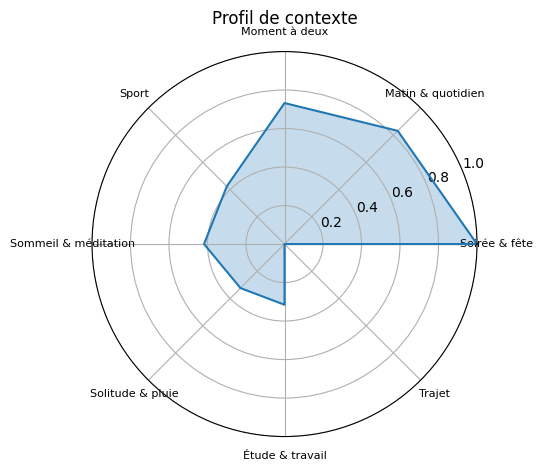

In [13]:
def radar(scores, titre):
    noms = list(scores)
    valeurs = list(scores.values()) + [list(scores.values())[0]]
    angles = np.linspace(0, 2 * np.pi, len(noms), endpoint=False).tolist()
    angles += angles[:1]
    fig, ax = plt.subplots(figsize=(5, 5), subplot_kw={"polar": True})
    ax.plot(angles, valeurs)
    ax.fill(angles, valeurs, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(noms, fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(titre, pad=20)
    plt.show()

radar(resultat["profil"]["blocs_humeur"], "Profil d'humeur")
radar(resultat["profil"]["blocs_contexte"], "Profil de contexte")

## 6. Cas d'usage

On teste des profils très différents. Avec MiniLM on avait obtenu :
- sportif : Lose Yourself (Eminem), Galvanize (Chemical Brothers), Invaders Must Die (Prodigy), puis avec nos blocs v2 Till I Collapse (Eminem), Invaders Must Die, Self vs Self (Pendulum). Cohérent, mais l'humeur dominante était *Colère & défoulement* plutôt qu'*Énergie & motivation* (sûrement le mot "rage")
- chagrin : On the Nature of Daylight (Max Richter), Everybody Hurts (R.E.M.), Someone Like You (Adele). Très cohérent
- soirée entre amis : Last Last (Burna Boy), Levitating (Dua Lipa), Tití Me Preguntó (Bad Bunny). Cohérent
- soirée romantique : Woman in Love (Barbra Streisand), Best Part (Daniel Caesar), Say You, Say Me (Lionel Richie). Cohérent après correction des blocs

In [14]:
def cas(humeur, contexte="", genres=(), energie=None):
    return {"textes": [humeur, contexte], "humeur": [humeur], "contexte": [contexte] if contexte else [],
            "genres": list(genres), "artistes": [], "energie": energie}

cas_usage = {
    "Sportif motivé": cas("J'ai besoin d'une musique puissante qui me donne la rage de me dépasser.",
                          "Séance de musculation à la salle", ["Hip-hop / Rap", "Électro / House"], 5),
    "Chagrin un jour de pluie": cas("Je viens de vivre une rupture. Je me sens seul et nostalgique.",
                                    "Seul chez moi, il pleut dehors", energie=1),
    "Soirée entre amis": cas("On est de bonne humeur et on veut danser toute la nuit !",
                             "Soirée chez des amis le samedi soir", ["Pop", "Afro / Reggae / Latino"], 5),
    "Soirée romantique": cas("Une ambiance tendre et intime, un peu rêveuse.",
                             "Dîner en tête-à-tête avec ma copine", ["R&B / Soul / Funk"], 2),
}
for nom, requete in cas_usage.items():
    print("\n-----", nom, "-----")
    afficher(recommender.recommander(sm, requete))


----- Sportif motivé -----
PROFIL : Vous cherchez une ambiance « Colère & défoulement » / « Énergie & motivation », pour un contexte « Sport », énergie 5/5, genres : Hip-hop / Rap, Électro / House.

1. Galvanize - The Chemical Brothers [Électro / House]
   score : 0.874 - Très forte correspondance
   critères : {'description': 0.787, 'humeur': 0.917, 'contexte': 0.766, 'genre': 1.0, 'energie': 1.0}
   principaux critères : Proche de votre description, Humeur, Genre préféré
   « Galvanize » de The Chemical Brothers est recommandé car sa description est proche de ce que vous avez écrit (79%), son ambiance « Énergie & motivation » correspond à votre humeur (92%), c'est du Électro / House, un genre que vous aimez. Très forte correspondance (score 87%).

2. Lose Yourself - Eminem [Hip-hop / Rap]
   score : 0.816 - Très forte correspondance
   critères : {'description': 0.488, 'humeur': 0.917, 'contexte': 1.0, 'genre': 1.0, 'energie': 1.0}
   principaux critères : Humeur, Genre préféré, Con

Résultats avec mpnet :
- **sportif** : Galvanize (Chemical Brothers), Lose Yourself (Eminem), Stronger (Kanye West). L'humeur dominante est encore *Colère & défoulement* (le mot "rage"), mais *Énergie & motivation* arrive juste derrière et c'est elle qui ressort dans les explications
- **chagrin** : when the party's over (Billie Eilish), Someone Like You (Adele), On the Nature of Daylight (Max Richter). Très cohérent
- **soirée entre amis** : Last Last (Burna Boy), Levitating (Dua Lipa), One More Time (Daft Punk). Daft Punk n'est pas dans les genres cochés (genre = 0) mais sa description correspond à 100 %. C'est un bon exemple de **découverte** : le score sémantique peut faire remonter un morceau en dehors des genres choisis
- **soirée romantique** : Thinkin Bout You (Frank Ocean), Woman in Love (Barbra Streisand), Best Part (Daniel Caesar). Cohérent

Par rapport à MiniLM, la description est maintenant souvent le premier critère : avec la calibration, ce critère n'est plus écrasé par les autres.

### Est-ce vraiment sémantique ?
On reprend la phrase de l'erreur 3, qui ne contient aucun mot du dataset, et on compare :
- une méthode par mots-clés : on compte les mots de la phrase présents dans la description
- le score sémantique de la partie 3
- notre système complet

In [15]:
texte = "J'ai besoin de souffler, de laisser retomber la pression."

#méthode naïve : nombre de mots communs (mots de plus de 3 lettres)
mots = {m for m in re.findall(r"\w+", texte.lower()) if len(m) > 3}
mots_communs = sm.tracks["description"].str.lower().apply(lambda d: sum(m in d for m in mots))
print("morceaux avec au moins 1 mot commun :", (mots_communs > 0).sum(), "/", len(sm.tracks))

#score sémantique seul
pd.DataFrame({"morceau": sm.tracks["title"], "mood": sm.tracks["mood"], "mots communs": mots_communs,
              "score sémantique": sm.semantic_score([texte]).round(3)}).sort_values("score sémantique", ascending=False).head(8)

morceaux avec au moins 1 mot commun : 5 / 684


,morceau,mood,mots communs,score sémantique
325,The Air That I Breathe,romantique|mélancolique|introspectif,0,0.497
344,Breathe (2 AM),doux|mélancolique|introspectif,0,0.472
518,Keep Breathing,mélancolique|triste|doux,0,0.431
544,Give It Away,doux|calme|serein,0,0.430
536,Surfing on a Rocket,doux|joyeux|entraînant,0,0.422
478,Let It Be Me,doux|calme|serein,0,0.389
538,I Have Seen,doux|calme|serein,0,0.386
15,Stressed Out,optimiste|joyeux|entraînant|dansant,0,0.385


In [16]:
#système complet
afficher(recommender.recommander(sm, cas(texte)))

PROFIL : Vous cherchez une ambiance « Calme & détente » / « Rêverie & évasion ».

1. Give It Away - Zero 7 [Lo-fi / Chill]
   score : 0.773 - Très forte correspondance
   critères : {'description': 0.584, 'humeur': 1.0}
   principaux critères : Humeur, Proche de votre description
   « Give It Away » de Zero 7 est recommandé car son ambiance « Calme & détente » correspond à votre humeur (100%), sa description est proche de ce que vous avez écrit (58%). Très forte correspondance (score 77%).

2. Let It Be Me - Ray LaMontagne [Indie / Folk / Country]
   score : 0.68 - Très forte correspondance
   critères : {'description': 0.413, 'humeur': 1.0}
   principaux critères : Humeur, Proche de votre description
   « Let It Be Me » de Ray LaMontagne est recommandé car son ambiance « Calme & détente » correspond à votre humeur (100%), sa description est proche de ce que vous avez écrit (41%). Très forte correspondance (score 68%).

3. Good Riddance (Time of Your Life) - Green Day [Rock]
   score :

Résultat :
- mots-clés : seulement 5 morceaux sur 684 ont un mot en commun, cette méthode ne sert à rien ici
- score sémantique seul : The Air That I Breathe, Breathe (2 AM), Keep Breathing. Le modèle multilingue relie "souffler" au mot anglais "breathe" dans les titres. Ces morceaux sont doux et mélancoliques, donc ce n'est pas absurde, et le morceau metal *Duality* qu'on avait avec MiniLM a disparu
- système complet : profil *Calme & détente*, avec Give It Away (Zero 7), Let It Be Me (Ray LaMontagne) et Good Riddance (Green Day). Ce sont des morceaux calmes : **l'erreur 3 est corrigée**. Avec MiniLM on avait *Colère & défoulement* et Rage Against the Machine.

C'est un bon exemple pour l'oral : la phrase n'a aucun mot du dataset, la recherche par mots-clés échoue, et l'analyse sémantique trouve quand même des morceaux qui correspondent à l'intention.

Limite qui reste : quand une phrase mélange un état ("la pression") et un souhait ("souffler"), le système ne sait pas lequel suivre. La partie 3 gère ça dans le chatbot en séparant l'état et le souhait.

## 7. Partie 5 : l'API FastAPI

Le front est en Next.js, il ne peut pas exécuter notre Python. Il envoie donc les réponses du questionnaire en JSON à l'API, l'API lance le moteur de la partie 4 et renvoie le résultat en JSON.

Le front avait déjà défini le format des échanges (`frontend/docs/api-contract.md`) et l'avait codé dans son interface. On a donc adapté l'API à ce format plutôt que l'inverse :
- route `POST /recommendations`
- champs en anglais : `moods`, `description`, `genres`, `listeningContext`, `contextDescription`, `energyLevel`, `favoriteArtists`, `vocalPreference`, `additionalPreferences`
- scores en pourcentage, avec `moodScore`, `genreScore`, `contextScore`, une liste `reasons` et une pochette `coverUrl`

Ce qu'on a dû traduire :

| Champ du front | Ce qu'on en fait |
|---|---|
| `moods` (Happy, Sad, Calm...) | transformés en phrases ("je suis triste"...) et ajoutés au texte d'humeur, pour rester sémantique |
| `listeningContext` (Studying, Exercising...) | transformé en phrase ("pour réviser et étudier"...) et ajouté au texte de contexte |
| `genres` (Lo-Fi, Hip-Hop...) | traduits vers les genres du dataset ("Lo-fi / Chill", "Hip-hop / Rap"...) |
| `favoriteArtists` | découpé sur les virgules |
| `vocalPreference` = Instrumental | ajoute "musique instrumentale sans paroles" au texte |
| `energyLevel` | critère énergie |

On ajoute aussi `spotifyTrackId` quand le morceau a un vrai identifiant Spotify (22 caractères), le front sait alors le lire. En plus du contrat, on renvoie `profile` avec les scores par bloc, pour un diagramme radar.

Pourquoi FastAPI : les données reçues sont vérifiées automatiquement avec Pydantic (énergie entre 1 et 5...), une page de documentation est générée toute seule sur `/docs`, et c'est du Python comme le reste.

In [17]:
%%writefile backend/schemas/__init__.py
"""Formats de la requête et de la réponse de l'API (partie 5).

Ils suivent le contrat proposé par le front : frontend/docs/api-contract.md
(mêmes noms de champs que frontend/types/questionnaire.ts et frontend/types/music.ts).
"""
from typing import Optional

from pydantic import BaseModel, Field


#ce que le questionnaire du front envoie
class Questionnaire(BaseModel):
    moods: list[str] = []
    description: str = Field(min_length=3, max_length=1000)
    genres: list[str] = []
    listeningContext: str = ""
    contextDescription: str = ""
    energyLevel: int = Field(3, ge=1, le=5)
    favoriteArtists: str = ""
    vocalPreference: str = "No preference"
    additionalPreferences: str = ""


class Recommendation(BaseModel):
    id: str
    rank: int
    title: str
    artist: str
    coverUrl: str
    genre: str
    mood: str
    score: int          #tous les scores sont en pourcentage (0-100) comme demandé par le front
    moodScore: int
    genreScore: int
    contextScore: int
    explanation: str
    reasons: list[str]
    spotifyTrackId: Optional[str] = None


class Affinity(BaseModel):
    label: str
    score: int


#en plus du contrat : le profil par bloc, utile pour un diagramme radar
class ProfileDetails(BaseModel):
    dominantMood: str
    dominantContext: Optional[str] = None
    moodBlocks: dict[str, int]
    contextBlocks: dict[str, int]
    #partie 6 (profil utilisateur)
    emotion: Optional[str] = None           #émotion dominante détectée : colère, tristesse, stress…
    strategy: Optional[str] = None          #« réguler » (changer d'humeur) ou « accompagner »
    strategySource: Optional[str] = None    #« texte » (écrit par l'utilisateur) ou « défaut »
    intensity: Optional[int] = None         #1 à 3
    excludedGenres: list[str] = []
    instrumental: bool = False
    archetype: Optional[str] = None         #profil d'auditeur (data/archetypes.json)


class RecommendationResponse(BaseModel):
    recommendations: list[Recommendation]
    affinities: list[Affinity]
    profileSummary: str
    scenario: str
    isDemo: bool
    profile: ProfileDetails

Overwriting backend/schemas/__init__.py


In [18]:
%%writefile backend/main.py
"""API FastAPI de Moodify (partie 5).

Lancer depuis la racine du dépôt :
    uvicorn backend.main:app --reload --port 8000
Doc interactive pour tester : http://localhost:8000/docs
Côté front : mettre NEXT_PUBLIC_USE_MOCKS=false dans frontend/.env.local
"""
import json
import os
import sys
from pathlib import Path

from fastapi import FastAPI, HTTPException
from fastapi.middleware.cors import CORSMiddleware

#le module NLP de la partie 3 est dans src/moodify
sys.path.insert(0, str(Path(__file__).resolve().parents[1] / "src"))
from moodify.semantic import SemanticMatcher  # noqa: E402

from backend.recommendation.recommender import recommander  # noqa: E402
from backend.schemas import Questionnaire, RecommendationResponse  # noqa: E402

#chargé une seule fois au démarrage : dataset + modèle SBERT + embeddings du catalogue
#(MOODIFY_ENCODER=tfidf permet de tester sans télécharger le modèle)
sm = SemanticMatcher(os.getenv("MOODIFY_ENCODER", "sbert"))

app = FastAPI(title="Moodify API")

#sinon le navigateur bloque les appels du front (localhost:3000) vers l'API (localhost:8000)
app.add_middleware(CORSMiddleware, allow_origins=["*"], allow_methods=["*"], allow_headers=["*"])

#pochette de secours : le front a 4 images, on choisit selon le bloc d'humeur principal du morceau
POCHETTES = {
    "Calme & détente": "calm", "Rêverie & évasion": "calm", "Mélancolie & introspection": "melancholic",
    "Romance & sensualité": "melancholic", "Concentration": "focused",
}


#vraies pochettes (colonne cover_url du dataset, remplie par dataset_builder/covers.py)
COVER_URLS = dict(zip(sm.tracks["track_id"], sm.tracks["cover_url"])) if "cover_url" in sm.tracks else {}


def pochette(track_id, bloc):
    """Pochette Spotify du morceau si elle existe, sinon une des 4 images du front."""
    url = COVER_URLS.get(track_id)
    return url if isinstance(url, str) and url.startswith("https://") else f"/covers/{POCHETTES.get(bloc, 'energetic')}.svg"


def vers_requete(q: Questionnaire):
    """Questionnaire du front -> requête du moteur : le profil complet (humeur, contexte, préférences)
    est construit par la partie 6 (backend/personalization), on lui passe toutes les réponses."""
    return q.model_dump()


def pct(x):
    return int(round(100 * float(x)))


@app.get("/")
def accueil():
    return {"status": "ok", "nb_morceaux": len(sm.tracks), "encodeur": sm.encoder.name}


@app.post("/recommendations", response_model=RecommendationResponse, response_model_exclude_none=True)
def recommendations(q: Questionnaire):
    res = recommander(sm, vers_requete(q), top_k=3)
    recos = []
    for r in res["recommandations"]:
        c = r["criteres"]
        bloc = r["blocs_humeur"][0] if r["blocs_humeur"] else ""
        recos.append({
            "id": r["track_id"], "rank": r["rang"], "title": r["titre"], "artist": r["artiste"],
            "coverUrl": pochette(r["track_id"], bloc),
            "genre": r["genre"], "mood": (r["humeurs"] or [""])[0].capitalize(),
            "score": pct(r["score"]), "moodScore": pct(c.get("humeur", 0)),
            "genreScore": pct(c.get("genre", 0)), "contextScore": pct(c.get("contexte", 0)),
            "explanation": r["explication"], "reasons": r["principaux_criteres"],
            #les identifiants de 22 caractères sont de vrais identifiants Spotify
            "spotifyTrackId": r["track_id"] if len(r["track_id"]) == 22 else None,
        })

    def moyenne(cle):
        return int(round(sum(x[cle] for x in recos) / max(len(recos), 1)))

    p = res["profil"]
    return {
        "recommendations": recos,
        "affinities": [{"label": "Mood", "score": moyenne("moodScore")},
                       {"label": "Genre", "score": moyenne("genreScore")},
                       {"label": "Context", "score": moyenne("contextScore")},
                       {"label": "Overall", "score": moyenne("score")}],
        "profileSummary": p["synthese"],
        "scenario": "semantic",
        "isDemo": False,
        "profile": {"dominantMood": p["humeur_dominante"], "dominantContext": p["contexte_dominant"],
                    "moodBlocks": {b: pct(v) for b, v in p["blocs_humeur"].items()},
                    "contextBlocks": {b: pct(v) for b, v in p["blocs_contexte"].items()},
                    #partie 6
                    "emotion": p.get("emotion"), "strategy": p.get("strategie"),
                    "strategySource": p.get("strategie_source"),
                    "intensity": p.get("intensite"), "excludedGenres": p.get("genres_exclus", []),
                    "instrumental": p.get("instrumental", False),
                    "archetype": (p.get("archetype") or {}).get("nom")},
    }


@app.get("/tracks/{track_id}")
def morceau(track_id: str):
    ligne = sm.tracks[sm.tracks["track_id"] == track_id]
    if ligne.empty:
        raise HTTPException(status_code=404, detail="Morceau introuvable")
    #to_json gère les types numpy et les valeurs manquantes
    return json.loads(ligne.iloc[0].to_json())

Overwriting backend/main.py


### Test de l'API dans Colab
`TestClient` envoie des requêtes à l'API sans lancer de serveur. On utilise exactement l'exemple de requête du contrat du front.

In [19]:
from fastapi.testclient import TestClient
import backend.main as api
importlib.reload(api)

client = TestClient(api.app)
print(client.get("/").json())

#exemple de requête tiré de frontend/docs/api-contract.md
questionnaire = {
    "moods": ["Focused", "Calm"],
    "description": "I need soft, atmospheric music while studying tonight.",
    "genres": ["Ambient", "Lo-Fi"],
    "listeningContext": "Studying",
    "contextDescription": "Late evening before an exam",
    "energyLevel": 2,
    "favoriteArtists": "",
    "vocalPreference": "Instrumental",
    "additionalPreferences": "No heavy percussion",
}
rep = client.post("/recommendations", json=questionnaire)
print("statut :", rep.status_code)
reponse_api = rep.json()

#requête invalide : énergie à 9 alors que c'est de 1 à 5 -> 422
print("requête invalide :", client.post("/recommendations", json={"description": "calme", "energyLevel": 9}).status_code)

{'status': 'ok', 'nb_morceaux': 684, 'encodeur': 'sbert'}
statut : 200
requête invalide : 422


In [20]:
print(json.dumps(reponse_api, ensure_ascii=False, indent=2)[:3000])

{
  "recommendations": [
    {
      "id": "T003",
      "rank": 1,
      "title": "i'm closing my eyes",
      "artist": "potsu",
      "coverUrl": "/covers/calm.svg",
      "genre": "Lo-fi / Chill",
      "mood": "Calme",
      "score": 79,
      "moodScore": 67,
      "genreScore": 100,
      "contextScore": 65,
      "explanation": "« i'm closing my eyes » de potsu est recommandé car sa description est proche de ce que vous avez écrit (85%), son ambiance « Calme & détente » correspond à votre humeur (67%), c'est du Lo-fi / Chill, un genre que vous aimez. Très forte correspondance (score 79%).",
      "reasons": [
        "Proche de votre description",
        "Humeur",
        "Genre préféré"
      ]
    },
    {
      "id": "4eoDPVbSx04PlypRDwjsXk",
      "rank": 2,
      "title": "The Approaching Night",
      "artist": "Philip Wesley",
      "coverUrl": "/covers/calm.svg",
      "genre": "Ambient",
      "mood": "Apaisant",
      "score": 78,
      "moodScore": 69,
      "genreS

Le code 422 veut dire que Pydantic a refusé la requête, c'est ce qu'on veut.

Sur la réponse : le profil est *Calme & détente* / *Concentration* avec le contexte *Étude & travail*, ce qui correspond bien à "studying tonight" et à la case Studying. Le premier morceau (`T003`) fait partie du jeu gold écrit à la main : il n'a pas d'identifiant Spotify, donc pas de champ `spotifyTrackId`. Les deux autres en ont un.

Remarque : l'exemple du front est en anglais. Le modèle est multilingue, donc ça marche, mais nos explications sont en français.

### Lancer l'API avec le front
Sur un ordinateur, à la racine du dépôt :
```
pip install -r requirements.txt
uvicorn backend.main:app --reload --port 8000
```
Puis dans `frontend/`, créer un fichier `.env.local` avec `NEXT_PUBLIC_USE_MOCKS=false` et `NEXT_PUBLIC_API_URL=http://localhost:8000`, et lancer le front (`npm run dev`). La doc de l'API est sur http://localhost:8000/docs.

## 8. Résumé pour l'oral

**En quelques phrases** : l'utilisateur remplit le questionnaire du front (humeur en texte libre, humeurs cochées, contexte, genres, énergie). L'API traduit ses réponses et les envoie au moteur. Le moteur utilise le module NLP de la partie 3 (SBERT mpnet) pour comparer ses textes aux morceaux et aux blocs d'humeur et de contexte, comme les blocs de compétences de l'exemple du sujet. On combine 6 critères avec Score = somme(Wi x Si) / somme(Wi), dont 70 % de sémantique, et on renvoie le top 3 avec le score, les principaux critères et une explication.

**Difficultés rencontrées** :
1. le modèle donne trop d'importance au mot "musique" par rapport à l'émotion : 0.72 entre mélancolique et fête avec MiniLM, encore 0.67 avec mpnet. Amélioré mais pas résolu
2. des contextes mal reconnus : la soirée romantique est corrigée, mais "je révise tard le soir" donne encore *Soirée & fête*. Dans l'application, la case Studying compense
3. l'état et le souhait mélangés : "souffler" donnait de la colère avec MiniLM, mpnet donne bien du calme
4. des scores bruts très serrés : calibration du score sémantique (bornes de la partie 3) et normalisation min-max du profil. L'histogramme montre que seuls ~5 morceaux sur 684 dépassent 0.65
5. l'intégration : le front avait déjà son format, on a adapté l'API et traduit ses listes (genres, humeurs, contextes)

**Questions possibles** :
- Pourquoi mpnet ? La partie 3 l'a comparé à 5 autres modèles, c'est le meilleur sur les paraphrases et le jeu gold.
- Pourquoi ces poids ? 70 % sémantique comme demandé dans le sujet, l'artiste n'est qu'un bonus.
- Et si l'utilisateur ne remplit pas tout ? Le critère est retiré de la formule.
- Comment sont faites les explications ? Avec des phrases toutes faites remplies avec les scores, sans IA générative.

**Limites et améliorations** :
- poids choisis à la main, on pourrait les ajuster avec des retours d'utilisateurs
- le contexte "tard le soir" est encore confondu avec la soirée
- le bloc *Concentration* n'existe pas dans les `mood_blocks` du dataset
- les négations ("pas de rap") ne sont pas gérées par le score, seulement par le chatbot de la partie 3
- bonus possible : un LLM pour reformuler les explications (bonus A du sujet)